# 06 - Evaluation summary

One table, one figure: unweighted vs. weighted conformal prediction on the faint target set, at alpha=0.1 (nominal 90% coverage).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

unw = pd.read_parquet("../data/processed/target_unweighted.parquet")
wtd = pd.read_parquet("../data/processed/target_weighted.parquet")
uw_metrics = json.load(open("../data/processed/unweighted_metrics.json"))
w_metrics = json.load(open("../data/processed/weighted_metrics.json"))

df = unw.merge(wtd[["id", "field", "z_lower_w", "z_upper_w", "covered_w"]], on=["id", "field"])

## Headline comparison

In [2]:
summary = pd.DataFrame([
    {"method": "unweighted", "coverage": uw_metrics["coverage_unweighted"], "mean_width": uw_metrics["width_unweighted"]},
    {"method": "weighted", "coverage": w_metrics["coverage_weighted"], "mean_width": w_metrics["width_weighted"]},
])
summary["nominal"] = 0.90
summary

,method,coverage,mean_width,nominal
0,unweighted,0.429219,0.740295,0.9
1,weighted,0.735013,1.219993,0.9


In [3]:
print(f"domain classifier AUC: {w_metrics['auc']:.4f}  (near 1.0 -> near-degenerate weights)")
print(f"effective calibration sample size after weighting: {w_metrics['n_eff']:.1f} "
      f"of {len(unw.merge(wtd, on=['id','field']))} target points worth of calibration support")

domain classifier AUC: 0.9999  (near 1.0 -> near-degenerate weights)
effective calibration sample size after weighting: 48.3 of 1985 target points worth of calibration support


## Coverage by magnitude bin -- where does each method fail?

In [4]:
by_bin = df.groupby("mag_bin")[["covered", "covered_w"]].mean()
by_bin.columns = ["unweighted", "weighted"]
by_bin

,unweighted,weighted
mag_bin,,
"(21.575, 22.053]",0.617706,0.857143
"(22.053, 22.515]",0.489919,0.826613
"(22.515, 23.027]",0.370968,0.778226
"(23.027, 26.491]",0.237903,0.477823


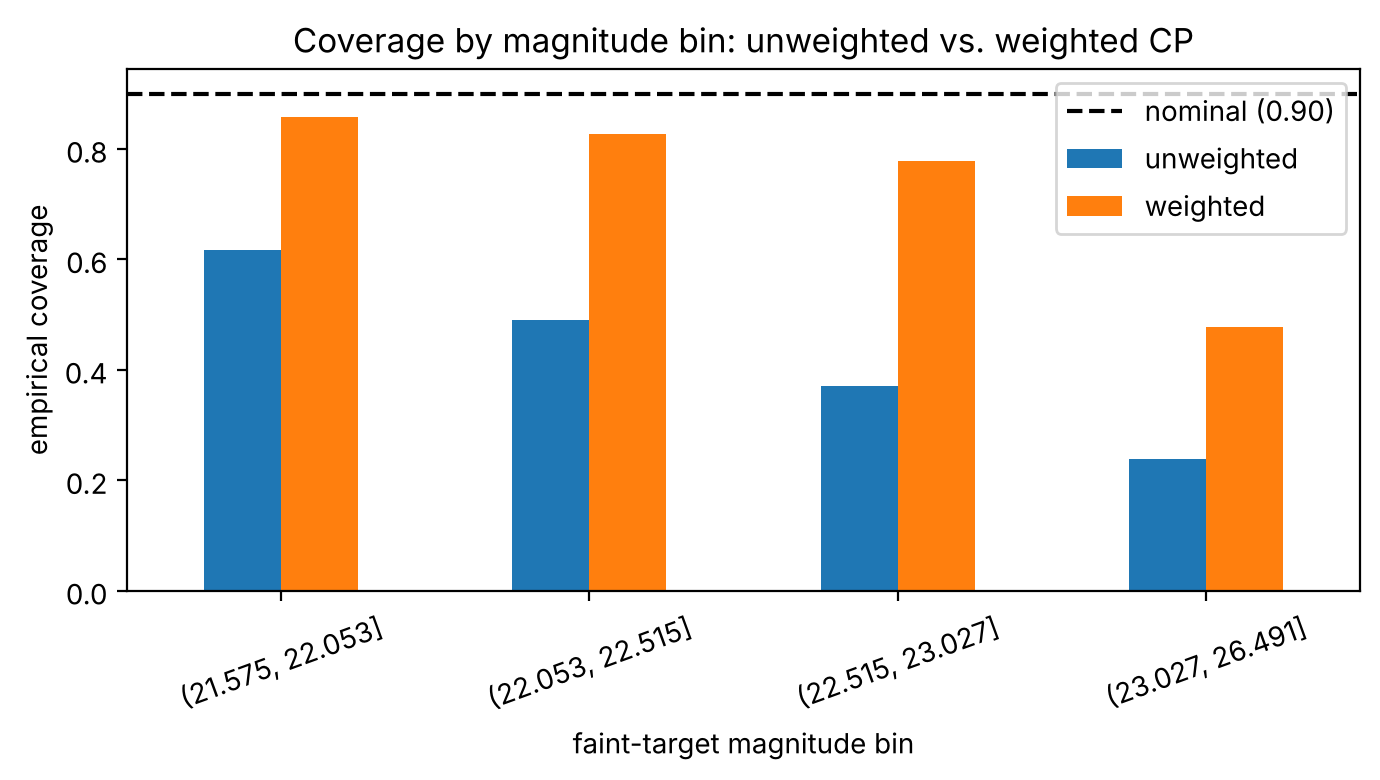

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
by_bin.plot.bar(ax=ax)
ax.axhline(0.90, color="black", ls="--", label="nominal (0.90)")
ax.set_ylabel("empirical coverage"); ax.set_xlabel("faint-target magnitude bin")
ax.set_title("Coverage by magnitude bin: unweighted vs. weighted CP")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
plt.savefig("../figures/coverage_by_bin.png", dpi=150)
plt.show()

## Reading the result

1. **Unweighted coverage collapses** from a nominal 90% to ~43% on the faint target, worsening monotonically with magnitude -- the guarantee fails exactly as covariate shift predicts.
2. **Weighted CP recovers most of it** (~74% overall), at the cost of ~65% wider intervals -- the width is the price of the correction, not a free lunch.
3. **The correction has a limit**: the faintest quartile is still well under nominal, and the domain classifier's AUC is near 1.0 with effective calibration sample size collapsed to a small fraction of its nominal size. There's effectively no bright analog for the faintest faint objects, so no amount of reweighting the existing calibration set can fix that region.